***Membaca Data***

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

In [ ]:
data = pd.read_csv("/content/drive/MyDrive/Data Tugas1/Dataset Pengiriman Makanan Beku.csv")
raw = data.copy()
data.head()

,id_pengiriman,kategori_muatan,hub_asal,hub_tujuan,zona_asal,layanan,status_pengiriman,waktu_berangkat,batas_sla,waktu_tiba,...,nilai_muatan_rp,tagihan_rp,sumber_manifest,versi_update_utc,suhu_awal,unit_suhu_awal,koreksi_awal_c,suhu_lanjutan,unit_suhu_lanjutan,koreksi_lanjutan_c
0,KRM00238,Segar,SBY,DPS,WIB,Prioritas,Retur,2026-03-12T00:15:00Z,2026-03-12T06:15:00Z,2026-03-12T08:15:00Z,...,650000,464500,Aplikasi Hub,2026-03-13T08:15:00Z,12.076,C,-1.20,50.685,NaN,-1.20
1,KRM00474,NaN,SBY,GSK,WIB,Ekonomi,Dibatalkan,NaN,2026-04-20T18:10:00Z,NaN,...,3887000,0,Aplikasi Hub,2026-04-21T12:10:00Z,NaN,NaN,NaN,NaN,NaN,NaN
2,KRM00015,Beku,DPS,SBY,WITA,Ekonomi,Terkirim,2026-02-03T10:55:00Z,2026-02-04T04:55:00Z,2026-02-04T14:55:00Z,...,23457000,1755000,ERP,2026-02-05T14:55:00Z,-5.129,F,-0.35,-15.55,NaN,-0.35
3,KRM00687,Segar,DPS,GSK,WITA,Ekonomi,Terkirim,2026-05-26T03:25:00Z,2026-05-26T21:25:00Z,2026-05-26T11:25:00Z,...,2990000,177500,ERP,2026-05-27T13:25:00Z,52.353,F,0.55,48.653,F,0.55
4,KRM00116,NaN,MKS,GSK,WITA,Ekonomi,Retur,2026-02-20T09:05:00Z,2026-02-21T03:05:00Z,2026-02-20T17:05:00Z,...,1073000,184000,Aplikasi Hub,2026-02-21T17:05:00Z,6.855,C,-1.20,39.486,F,-1.20


***Deteksi***

In [ ]:
# Memeriksa data
print(data.shape)
display(data.groupby("kategori_muatan")[["id_pengiriman"]].count())
display(data.groupby("satuan_berat")[["id_pengiriman"]].count())
data.isnull().sum()

(202, 28)


,id_pengiriman
kategori_muatan,
FROZEN,6
fresh,7
?,1
Beku,61
Chill,6
Dingin,60
Segar,42


,id_pengiriman
satuan_berat,
G,5
g,5
gram,12
kg,179
lbs,1


,0
id_pengiriman,0
kategori_muatan,19
hub_asal,0
hub_tujuan,8
zona_asal,0
layanan,15
status_pengiriman,0
waktu_berangkat,10
batas_sla,0
waktu_tiba,15


**Soal 1. Penulisan kategori dan satuan tidak konsisten**

In [ ]:
# DETEKSI 1 (Frekuensi sebelum  perbaikan)
display(data.groupby("kategori_muatan",dropna=False).count())
display(data.groupby("satuan_berat",dropna=False).count())

,id_pengiriman,hub_asal,hub_tujuan,zona_asal,layanan,status_pengiriman,waktu_berangkat,batas_sla,waktu_tiba,berat_aktual,...,nilai_muatan_rp,tagihan_rp,sumber_manifest,versi_update_utc,suhu_awal,unit_suhu_awal,koreksi_awal_c,suhu_lanjutan,unit_suhu_lanjutan,koreksi_lanjutan_c
kategori_muatan,,,,,,,,,,,,,,,,,,,,,
FROZEN,6,6,6,6,5,6,6,6,6,4,...,4,6,6,6,6,6,6,5,6,6
fresh,7,7,7,7,7,7,6,7,6,5,...,6,6,7,7,6,6,6,6,5,6
?,1,1,1,1,0,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
Beku,61,61,57,61,58,61,59,61,57,57,...,58,59,61,61,55,55,55,50,49,55
Chill,6,6,6,6,6,6,6,6,6,6,...,6,6,6,6,6,6,6,6,6,6
Dingin,60,60,58,60,57,60,57,60,55,56,...,55,57,60,60,55,55,55,48,51,55
Segar,42,42,40,42,38,42,41,42,40,41,...,39,39,42,42,39,39,39,33,38,39
NaN,19,19,19,19,16,19,16,19,16,17,...,19,19,19,19,16,16,16,12,16,16


,id_pengiriman,kategori_muatan,hub_asal,hub_tujuan,zona_asal,layanan,status_pengiriman,waktu_berangkat,batas_sla,waktu_tiba,...,nilai_muatan_rp,tagihan_rp,sumber_manifest,versi_update_utc,suhu_awal,unit_suhu_awal,koreksi_awal_c,suhu_lanjutan,unit_suhu_lanjutan,koreksi_lanjutan_c
satuan_berat,,,,,,,,,,,,,,,,,,,,,
G,5,5,5,4,5,5,5,5,5,5,...,4,5,5,5,5,5,5,5,5,5
g,5,5,5,5,5,5,5,5,5,5,...,5,4,5,5,5,5,5,4,4,5
gram,12,11,12,11,12,11,12,11,12,10,...,11,11,12,12,10,10,10,9,10,10
kg,179,161,179,173,179,165,179,170,179,166,...,167,172,179,179,163,163,163,143,152,163
lbs,1,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,0,1,1


In [ ]:
# SOLUSI 1A (Spasi lebih dan penanda kosong)
data = data.apply(lambda x: x.str.strip() if x.dtype == "object" else x)
data = data.apply(lambda x: x.str.replace(r" +", " ", regex=True) if x.dtype == "object" else x)
data = data.replace(r"(?i)^(?:|na|n/a|null|\?|—|-|tidak diisi)$", np.nan, regex=True)

data.head()

,id_pengiriman,kategori_muatan,hub_asal,hub_tujuan,zona_asal,layanan,status_pengiriman,waktu_berangkat,batas_sla,waktu_tiba,...,nilai_muatan_rp,tagihan_rp,sumber_manifest,versi_update_utc,suhu_awal,unit_suhu_awal,koreksi_awal_c,suhu_lanjutan,unit_suhu_lanjutan,koreksi_lanjutan_c
0,KRM00238,Segar,SBY,DPS,WIB,Prioritas,Retur,2026-03-12T00:15:00Z,2026-03-12T06:15:00Z,2026-03-12T08:15:00Z,...,650000,464500,Aplikasi Hub,2026-03-13T08:15:00Z,12.076,C,-1.20,50.685,NaN,-1.20
1,KRM00474,NaN,SBY,GSK,WIB,Ekonomi,Dibatalkan,NaN,2026-04-20T18:10:00Z,NaN,...,3887000,0,Aplikasi Hub,2026-04-21T12:10:00Z,NaN,NaN,NaN,NaN,NaN,NaN
2,KRM00015,Beku,DPS,SBY,WITA,Ekonomi,Terkirim,2026-02-03T10:55:00Z,2026-02-04T04:55:00Z,2026-02-04T14:55:00Z,...,23457000,1755000,ERP,2026-02-05T14:55:00Z,-5.129,F,-0.35,-15.55,NaN,-0.35
3,KRM00687,Segar,DPS,GSK,WITA,Ekonomi,Terkirim,2026-05-26T03:25:00Z,2026-05-26T21:25:00Z,2026-05-26T11:25:00Z,...,2990000,177500,ERP,2026-05-27T13:25:00Z,52.353,F,0.55,48.653,F,0.55
4,KRM00116,NaN,MKS,GSK,WITA,Ekonomi,Retur,2026-02-20T09:05:00Z,2026-02-21T03:05:00Z,2026-02-20T17:05:00Z,...,1073000,184000,Aplikasi Hub,2026-02-21T17:05:00Z,6.855,C,-1.20,39.486,F,-1.20


In [ ]:
# SOLUSI 1B (kapital dan penulisan awal kategori)
mapping = {
 "kategori_muatan":{"frozen":"beku","chill":"dingin","fresh":"segar"},
 "layanan":{"eco":"ekonomi","reguler":"standar","exp":"prioritas"},
 "status_pengiriman":{"delivered":"terkirim","return":"retur","cancel":"dibatalkan"},
 "hub_asal":{"gresik":"gsk","surabaya":"sby","denpasar":"dps","makassar":"mks"},
 "hub_tujuan":{"gresik":"gsk","surabaya":"sby","denpasar":"dps","makassar":"mks"},
 "satuan_berat":{"gram":"g"},
 "unit_suhu_awal":{"celsius":"c","fahrenheit":"f","kelvin":"k"},
 "unit_suhu_lanjutan":{"celsius":"c","fahrenheit":"f","kelvin":"k"}
}
for kolom, alias in mapping.items():
    data[kolom] = data[kolom].str.lower().str.replace("°", "", regex=False).str.strip().replace(alias)


data.groupby("kategori_muatan",dropna=False).count()

,id_pengiriman,hub_asal,hub_tujuan,zona_asal,layanan,status_pengiriman,waktu_berangkat,batas_sla,waktu_tiba,berat_aktual,...,nilai_muatan_rp,tagihan_rp,sumber_manifest,versi_update_utc,suhu_awal,unit_suhu_awal,koreksi_awal_c,suhu_lanjutan,unit_suhu_lanjutan,koreksi_lanjutan_c
kategori_muatan,,,,,,,,,,,,,,,,,,,,,
beku,67,67,61,67,62,67,65,67,63,60,...,61,65,67,67,61,61,61,55,55,61
dingin,66,66,64,66,63,66,63,66,61,62,...,60,63,66,66,61,61,61,54,57,61
segar,49,49,47,49,45,49,47,49,46,46,...,44,45,49,49,45,45,45,39,43,45
NaN,20,20,20,20,16,20,17,20,17,17,...,19,20,20,20,17,17,17,13,17,17


In [ ]:
# DETEKSI DAN SOLUSI 1C (Kategori yang tidak sesuai daftar valid)
for kolom, valid in {
    "kategori_muatan":["beku","dingin","segar"],
    "layanan":["ekonomi","standar","prioritas"],
    "satuan_berat":["kg","g"],
    "unit_suhu_awal":["c","f","k"],"unit_suhu_lanjutan":["c","f","k"]
}.items():
    salah = data[kolom].notna() & ~data[kolom].isin(valid)
    display(data.loc[salah, ["id_pengiriman", kolom]])
    data.loc[salah, kolom] = np.nan

display(data.groupby("kategori_muatan",dropna=False)[["id_pengiriman"]].count())

,id_pengiriman,kategori_muatan


,id_pengiriman,layanan
80,KRM00546,oversize


,id_pengiriman,satuan_berat
153,KRM00514,lbs


,id_pengiriman,unit_suhu_awal


,id_pengiriman,unit_suhu_lanjutan


,id_pengiriman
kategori_muatan,
beku,67
dingin,66
segar,49
NaN,20


In [ ]:
#Cek hasil
data.groupby("kategori_muatan", dropna=False)[["id_pengiriman"]].count()

,id_pengiriman
kategori_muatan,
beku,67
dingin,66
segar,49
NaN,20


**Soal 2. Pada satu id pengiriman hanya memiliki beberapa catatan**

In [ ]:
# DETEKSI (Memeriksa ID yang tercatat lebih dari sekali)
data["id_pengiriman"] = data["id_pengiriman"].str.upper().str.replace("-", "", regex=False)
data["versi_update_utc"] = pd.to_datetime(data["versi_update_utc"], utc=True, errors="coerce")
print('Jumlah baris duplikat:', raw.duplicated().sum())
display(data[data.duplicated("id_pengiriman",keep=False)][["id_pengiriman","versi_update_utc"]])

Jumlah baris duplikat: 6


,id_pengiriman,versi_update_utc
3,KRM00687,2026-05-27 13:25:00+00:00
8,KRM00614,2026-05-15 10:15:00+00:00
9,KRM00698,2026-05-29 04:45:00+00:00
10,KRM00681,2026-05-26 12:00:00+00:00
11,KRM00698,2026-05-29 04:45:00+00:00
12,KRM00690,2026-05-27 12:00:00+00:00
13,KRM00687,2026-05-27 11:25:00+00:00
27,KRM00690,2026-05-27 10:00:00+00:00
30,KRM00635,2026-05-18 18:20:00+00:00
34,KRM00695,2026-05-28 21:30:00+00:00


In [ ]:
#SOLUSI
# Memilih catatan terbaru dan memisahkan catatan yang masih perlu diperiksa
print('Jumlah baris duplikat:', raw.duplicated().sum())
data = data.drop_duplicates().copy()
terbaru = data.groupby("id_pengiriman")["versi_update_utc"].transform("max")
data = data[data["versi_update_utc"].eq(terbaru)].copy()
data_perlu_dicek = data[data.duplicated("id_pengiriman", keep=False)].copy()
data = data[~data["id_pengiriman"].isin(data_perlu_dicek["id_pengiriman"])].copy()
print('Jumlah ID yang perlu dicek:', data_perlu_dicek["id_pengiriman"].nunique(), '| Jumlah ID yang digunakan:', data["id_pengiriman"].nunique())
display(data_perlu_dicek[["id_pengiriman","versi_update_utc","jarak_km"]])

Jumlah baris duplikat: 6
Jumlah ID yang perlu dicek: 4 | Jumlah ID yang digunakan: 176


,id_pengiriman,versi_update_utc,jarak_km
9,KRM00698,2026-05-29 04:45:00+00:00,429
11,KRM00698,2026-05-29 04:45:00+00:00,450
34,KRM00695,2026-05-28 21:30:00+00:00,73
103,KRM00696,2026-05-28 05:15:00+00:00,295
105,KRM00697,2026-05-29 08:10:00+00:00,276
114,KRM00695,2026-05-28 21:30:00+00:00,52
145,KRM00696,2026-05-28 05:15:00+00:00,274
195,KRM00697,2026-05-29 08:10:00+00:00,255


In [ ]:
# Cek hasil
print('Jumlah pengiriman yang digunakan:',len(data))
print('Semua ID sudah berbeda:',data["id_pengiriman"].is_unique)
print('Jumlah ID yang perlu dicek:',data_perlu_dicek["id_pengiriman"].nunique())

Jumlah pengiriman yang digunakan: 176
Semua ID sudah berbeda: True
Jumlah ID yang perlu dicek: 4


**Soal 3. Angka desimal tersimpan dengan format berbeda**

In [ ]:
#DETEKSI
display(data[["berat_aktual","jarak_km","suhu_awal"]].dtypes)
display(data[["berat_aktual","jarak_km","suhu_awal"]].head(10))

,0
berat_aktual,float64
jarak_km,float64
suhu_awal,float64


,berat_aktual,jarak_km,suhu_awal
0,30.987,253.0,12.076
1,31.075,101.0,NaN
2,215.000,43.0,-5.129
3,19.640,433.0,52.353
4,8.607,543.0,6.855
5,11.352,266.0,5.716
6,NaN,53.0,-24.022
7,NaN,43.0,-2.361
8,2.881,36.0,NaN
10,16.611,142.0,13.079


In [ ]:
#SOLUSI DAN CEK HASIL
kolom_angka = [
    "berat_aktual", "jarak_km", "suhu_awal", "suhu_lanjutan",
    "koreksi_awal_c", "koreksi_lanjutan_c",
    "panjang_cm", "lebar_cm", "tinggi_cm"
]
angka_sebelum = data[kolom_angka].copy()
for kolom in kolom_angka:
    nilai = data[kolom].astype("string").str.strip()
    nilai = nilai.str.replace(r"(?i)^rp\s*", "", regex=True)
    koma = nilai.str.contains(",", regex=False, na=False)
    nilai.loc[koma] = nilai.loc[koma].str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    data[kolom] = pd.to_numeric(nilai, errors="coerce").astype(float)

display(data[kolom_angka].head())
for kolom in kolom_angka:
    gagal = angka_sebelum[kolom].notna() & data[kolom].isna()
    print(kolom, "gagal konversi:", gagal.sum())
    display(angka_sebelum.loc[gagal, [kolom]])

,berat_aktual,jarak_km,suhu_awal,suhu_lanjutan,koreksi_awal_c,koreksi_lanjutan_c,panjang_cm,lebar_cm,tinggi_cm
0,30.987,253.0,12.076,50.685,-1.20,-1.20,27.0,58.0,25.0
1,31.075,101.0,NaN,NaN,NaN,NaN,81.0,32.0,26.0
2,215.000,43.0,-5.129,-15.550,-0.35,-0.35,75.0,32.0,42.0
3,19.640,433.0,52.353,48.653,0.55,0.55,45.0,23.0,32.0
4,8.607,543.0,6.855,39.486,-1.20,-1.20,72.0,39.0,49.0


berat_aktual gagal konversi: 0


,berat_aktual


jarak_km gagal konversi: 0


,jarak_km


suhu_awal gagal konversi: 0


... (9 outputs left out)

lebar_cm gagal konversi: 0


,lebar_cm


tinggi_cm gagal konversi: 0


,tinggi_cm


**Soal 4. Berat dan suhu belum memakai satuan yang sama**

In [ ]:
#DETEKSI
display(data.groupby("satuan_berat",dropna=False)[["id_pengiriman"]].count())
display(data.groupby("unit_suhu_awal",dropna=False)[["id_pengiriman"]].count())

,id_pengiriman
satuan_berat,
g,21
kg,154
NaN,1


,id_pengiriman
unit_suhu_awal,
c,90
f,54
k,16
NaN,16


In [ ]:
#SOLUSI & KONVERSI KE BERAT (KG)
data["berat_kg"] = data["berat_aktual"].replace(-999, np.nan)
gram = data["satuan_berat"].eq("g")
data.loc[gram, "berat_kg"] = data.loc[gram, "berat_kg"] / 1000
data.loc[data["satuan_berat"].isna(), "berat_kg"] = np.nan

display(data[["berat_aktual","satuan_berat","berat_kg"]].head(10))

,berat_aktual,satuan_berat,berat_kg
0,30.987,kg,30.987
1,31.075,kg,31.075
2,215.000,kg,215.000
3,19.640,kg,19.640
4,8.607,kg,8.607
5,11.352,kg,11.352
6,NaN,kg,NaN
7,NaN,kg,NaN
8,2.881,kg,2.881
10,16.611,kg,16.611


In [ ]:
#DETEKSI DI LUAR BATAS BERAT
berat_tidak_valid = data["berat_kg"].notna() & ((data["berat_kg"] <= 0) | (data["berat_kg"] > 300))
display(data.loc[berat_tidak_valid,["id_pengiriman","berat_aktual","satuan_berat","berat_kg"]])
print("Berat di luar batas:",berat_tidak_valid.sum())

,id_pengiriman,berat_aktual,satuan_berat,berat_kg


Berat di luar batas: 0


In [ ]:
#CEK HASIL
data["berat_kg"] = data["berat_kg"].where(data["berat_kg"].gt(0) & data["berat_kg"].le(300))


display(data[["berat_aktual","satuan_berat","berat_kg"]].head(10))

,berat_aktual,satuan_berat,berat_kg
0,30.987,kg,30.987
1,31.075,kg,31.075
2,215.000,kg,215.000
3,19.640,kg,19.640
4,8.607,kg,8.607
5,11.352,kg,11.352
6,NaN,kg,NaN
7,NaN,kg,NaN
8,2.881,kg,2.881
10,16.611,kg,16.611


In [ ]:
#DETEKSI JARAK DI LUAR BATAS
jarak_tidak_valid = data["jarak_km"].notna() & ((data["jarak_km"] <= 0) | (data["jarak_km"] > 1500))
display(data.loc[jarak_tidak_valid,["id_pengiriman","jarak_km"]])
print("Jarak di luar batas:",jarak_tidak_valid.sum())

,id_pengiriman,jarak_km
155,KRM00434,-10.0


Jarak di luar batas: 1


In [ ]:
data["jarak_valid"] = data["jarak_km"]
data["jarak_valid"] = data["jarak_valid"].where(data["jarak_valid"].gt(0) & data["jarak_valid"].le(1500))


display(data[["jarak_km","jarak_valid"]].head(10))

,jarak_km,jarak_valid
0,253.0,253.0
1,101.0,101.0
2,43.0,43.0
3,433.0,433.0
4,543.0,543.0
5,266.0,266.0
6,53.0,53.0
7,43.0,43.0
8,36.0,36.0
10,142.0,142.0


In [ ]:
#PERBAIKAN SATUAN SUHU
for tahap in ["awal", "lanjutan"]:
    suhu = data["suhu_"+tahap].replace(-999, np.nan)
    unit = data["unit_suhu_"+tahap]
    c = suhu.where(unit.eq("c"))
    c = c.fillna(((suhu-32)*5/9).where(unit.eq("f")))
    c = c.fillna((suhu-273.15).where(unit.eq("k")))
    koreksi = data["koreksi_"+tahap+"_c"]
    data["suhu_"+tahap+"_c"] = (c.where(c.between(-60,80)) + koreksi).where(
        data["status_pengiriman"].ne("dibatalkan")
    )
display(data[["berat_aktual","satuan_berat","berat_kg","suhu_awal","unit_suhu_awal","suhu_awal_c"]].head(10))

,berat_aktual,satuan_berat,berat_kg,suhu_awal,unit_suhu_awal,suhu_awal_c
0,30.987,kg,30.987,12.076,c,10.876000
1,31.075,kg,31.075,NaN,NaN,NaN
2,215.000,kg,215.000,-5.129,f,-20.977222
3,19.640,kg,19.640,52.353,f,11.857222
4,8.607,kg,8.607,6.855,c,5.655000
5,11.352,kg,11.352,5.716,c,5.366000
6,NaN,kg,NaN,-24.022,c,-23.772000
7,NaN,kg,NaN,-2.361,f,-18.139444
8,2.881,kg,2.881,NaN,NaN,NaN
10,16.611,kg,16.611,13.079,c,11.879000


**Soal 5. Missing numerik dan kategorik serta nilai di luar domain**

In [ ]:
#DETEKSI JUMLAH MISSING
display(data[["berat_kg","jarak_valid","kategori_muatan","suhu_awal_c","suhu_lanjutan_c"]].isnull().sum())
display(data.loc[data[["jarak_valid","kategori_muatan"]].isnull().any(axis=1),["id_pengiriman","jarak_valid","kategori_muatan"]].head(10))

,0
berat_kg,17
jarak_valid,20
kategori_muatan,19
suhu_awal_c,16
suhu_lanjutan_c,58


,id_pengiriman,jarak_valid,kategori_muatan
1,KRM00474,101.0,NaN
4,KRM00116,543.0,NaN
17,KRM00455,NaN,dingin
19,KRM00200,49.0,NaN
25,KRM00652,205.0,NaN
29,KRM00235,NaN,beku
32,KRM00318,NaN,beku
37,KRM00666,NaN,segar
46,KRM00631,NaN,dingin
47,KRM00604,96.0,NaN


In [ ]:
#DETEKSI NUMERIK & KATEGORIK
display(data[["berat_kg","jarak_valid","suhu_awal_c","suhu_lanjutan_c"]].describe().T)
display(data["kategori_muatan"].value_counts(dropna=False))
display(data["layanan"].value_counts(dropna=False))


,count,mean,std,min,25%,50%,75%,max
berat_kg,159.0,27.804836,30.242746,2.818000,11.857500,26.440000,34.842000,240.000
jarak_valid,156.0,253.410256,166.611693,26.000000,110.750000,212.500000,365.000000,548.000
suhu_awal_c,160.0,-3.327180,13.583018,-24.237222,-18.641750,3.631222,7.607306,13.261
suhu_lanjutan_c,118.0,-1.983026,14.493176,-24.277000,-16.593667,3.576500,8.866750,19.725


,count
kategori_muatan,
beku,60
dingin,58
segar,39
NaN,19


,count
layanan,
ekonomi,61
standar,53
prioritas,46
NaN,16


In [ ]:
#DETEKSI MISSING STRUKTURAL
batal = data["status_pengiriman"].eq("dibatalkan")
display(pd.DataFrame({
 "kosong_pada_batal":data.loc[batal,["suhu_awal_c","suhu_lanjutan_c"]].isna().sum(),
 "kosong_pada_status_lain":data.loc[~batal,["suhu_awal_c","suhu_lanjutan_c"]].isna().sum()
}))

,kosong_pada_batal,kosong_pada_status_lain
suhu_awal_c,9,7
suhu_lanjutan_c,9,49


In [ ]:
#SOLUSI MISSING MEDIAN JARAK
median_jarak = data["jarak_valid"].median()
data["jarak_diimputasi"] = data["jarak_valid"].isna()
data["jarak_isian"] = data["jarak_valid"].fillna(median_jarak)
print("Median jarak:", median_jarak)
display(data[["jarak_valid", "jarak_isian", "jarak_diimputasi"]].head(10))

Median jarak: 212.5


,jarak_valid,jarak_isian,jarak_diimputasi
0,253.0,253.0,False
1,101.0,101.0,False
2,43.0,43.0,False
3,433.0,433.0,False
4,543.0,543.0,False
5,266.0,266.0,False
6,53.0,53.0,False
7,43.0,43.0,False
8,36.0,36.0,False
10,142.0,142.0,False


In [ ]:
#SOLUSI KATEGORIK
modus_kategori = data["kategori_muatan"].mode().iloc[0]
data["kategori_diimputasi"] = data["kategori_muatan"].isna()
data["kategori_isian"] = data["kategori_muatan"].fillna(modus_kategori)
print("Modus kategori:", modus_kategori)
display(data[["kategori_muatan", "kategori_isian", "kategori_diimputasi"]].head(10))

Modus kategori: beku


,kategori_muatan,kategori_isian,kategori_diimputasi
0,segar,segar,False
1,NaN,beku,True
2,beku,beku,False
3,segar,segar,False
4,NaN,beku,True
5,dingin,dingin,False
6,beku,beku,False
7,beku,beku,False
8,dingin,dingin,False
10,segar,segar,False


In [ ]:
#HASIL PENGISIAN
display(pd.DataFrame({
    "sebelum":[data["jarak_valid"].isna().sum(), data["kategori_muatan"].isna().sum()],
    "sesudah":[data["jarak_isian"].isna().sum(), data["kategori_isian"].isna().sum()]
},index=["jarak","kategori"]))


,sebelum,sesudah
jarak,20,0
kategori,19,0


In [ ]:
#Perbandingan grafik sebelum dan sesudah pengisian missing value
jarak_sebelum = data["jarak_valid"].dropna()
jarak_sesudah = data["jarak_isian"].dropna()
bins_jarak = np.linspace(jarak_sebelum.min(), jarak_sebelum.max(), 16)
y_jarak = max(np.histogram(jarak_sebelum, bins=bins_jarak)[0].max(),
              np.histogram(jarak_sesudah, bins=bins_jarak)[0].max()) * 1.15
print("Nilai tersedia sebelum:",len(jarak_sebelum),"sesudah:",len(jarak_sesudah))

Nilai tersedia sebelum: 156 sesudah: 176


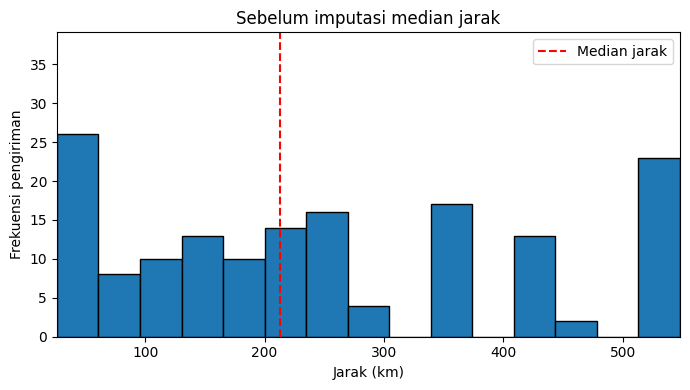

In [ ]:
#Histogram jarak sebelum imputasi
plt.figure(figsize=(7,4))
plt.hist(jarak_sebelum, bins=bins_jarak, edgecolor="black")
plt.axvline(median_jarak, color="red", linestyle="--", label="Median jarak")
plt.xlim(bins_jarak[0], bins_jarak[-1])
plt.ylim(0, y_jarak)
plt.xlabel("Jarak (km)")
plt.ylabel("Frekuensi pengiriman")
plt.title("Sebelum imputasi median jarak")
plt.legend()
plt.tight_layout()
plt.show()

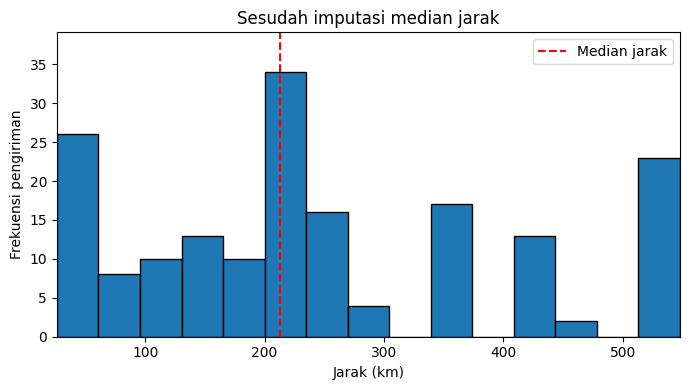

In [ ]:
#Histogram jarak sesudah imputasi
plt.figure(figsize=(7,4))
plt.hist(jarak_sesudah, bins=bins_jarak, edgecolor="black")
plt.axvline(median_jarak, color="red", linestyle="--", label="Median jarak")
plt.xlim(bins_jarak[0], bins_jarak[-1])
plt.ylim(0, y_jarak)
plt.xlabel("Jarak (km)")
plt.ylabel("Frekuensi pengiriman")
plt.title("Sesudah imputasi median jarak")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#GRAFIK KATEGORI
kategori_sebelum = data["kategori_muatan"].fillna("(Kosong)").value_counts()
kategori_sesudah = data["kategori_isian"].fillna("(Kosong)").value_counts()
urutan_kategori = ["beku", "dingin", "segar", "(Kosong)"]
y_kategori = max(kategori_sebelum.max(), kategori_sesudah.max()) * 1.18
print("Kategori kosong sebelum:",data["kategori_muatan"].isna().sum())
print("Kategori kosong sesudah:",data["kategori_isian"].isna().sum())

Kategori kosong sebelum: 19
Kategori kosong sesudah: 0


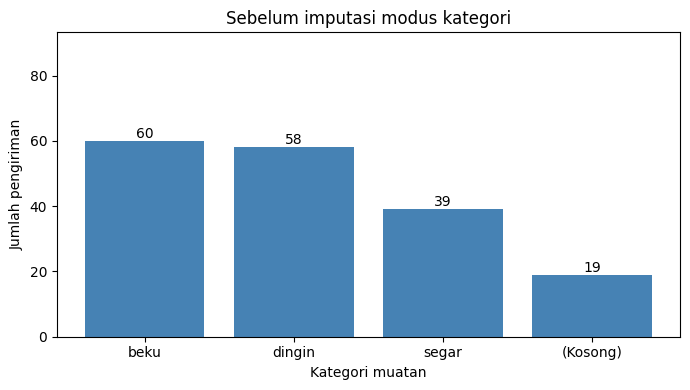

In [ ]:
#GRAFIK KATEGORI SEBELUM IMPUTASI
plt.figure(figsize=(7,4))
jumlah = kategori_sebelum.reindex(urutan_kategori, fill_value=0)
batang = plt.bar(urutan_kategori, jumlah, color="steelblue")
plt.bar_label(batang)
plt.ylim(0, y_kategori)
plt.xlabel("Kategori muatan")
plt.ylabel("Jumlah pengiriman")
plt.title("Sebelum imputasi modus kategori")
plt.tight_layout()
plt.show()

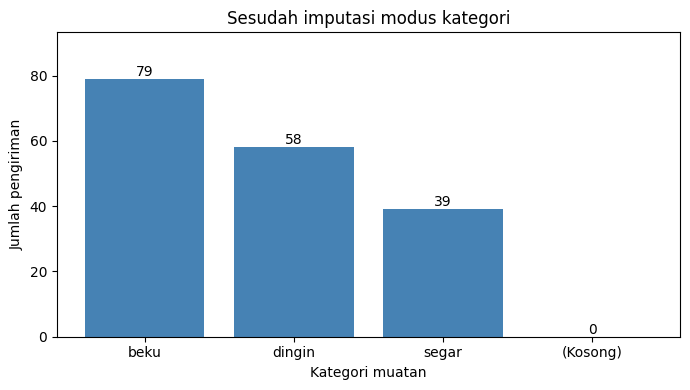

In [ ]:
#GRAFIK KATEGORI SESUDAH IMPUTASI
plt.figure(figsize=(7,4))
jumlah = kategori_sesudah.reindex(urutan_kategori, fill_value=0)
batang = plt.bar(urutan_kategori, jumlah, color="steelblue")
plt.bar_label(batang)
plt.ylim(0, y_kategori)
plt.xlabel("Kategori muatan")
plt.ylabel("Jumlah pengiriman")
plt.title("Sesudah imputasi modus kategori")
plt.tight_layout()
plt.show()

**Soal 6. Format waktu berbeda dan tanggal tiba mendahului keberangkatan**

In [ ]:
#DETEKSI
data[["id_pengiriman","waktu_berangkat","waktu_tiba","zona_asal"]].head(10)

,id_pengiriman,waktu_berangkat,waktu_tiba,zona_asal
0,KRM00238,2026-03-12T00:15:00Z,2026-03-12T08:15:00Z,WIB
1,KRM00474,NaN,NaN,WIB
2,KRM00015,2026-02-03T10:55:00Z,2026-02-04T14:55:00Z,WITA
3,KRM00687,2026-05-26T03:25:00Z,2026-05-26T11:25:00Z,WITA
4,KRM00116,2026-02-20T09:05:00Z,2026-02-20T17:05:00Z,WITA
5,KRM00199,06/03/2026 09:45:00,2026-03-06T16:45:00+08:00,WITA
6,KRM00509,2026-04-26T03:15:00Z,2026-04-26T07:15:00Z,WIB
7,KRM00577,2026-05-08T02:15:00Z,08/05/2026 21:15:00,WIB
8,KRM00614,NaN,NaN,WIB
10,KRM00681,2026-05-25T06:00:00Z,2026-05-25T10:00:00Z,WIB


In [ ]:
#SOLUSI  PERBAIKAN FORMAT DAN ZONA WAKTU
for kolom in ["waktu_berangkat", "waktu_tiba"]:
    teks = data[kolom].astype("string")
    data[kolom+"_utc"] = pd.to_datetime(teks, format="mixed", errors="coerce", utc=True)
    lokal = teks.str.contains("/", regex=False, na=False)
    data.loc[lokal, kolom+"_utc"] = pd.NaT
    for zona, tz in {"WIB":"Asia/Jakarta", "WITA":"Asia/Makassar"}.items():
        pilih = lokal & data["zona_asal"].eq(zona)
        waktu = pd.to_datetime(teks.loc[pilih], format="%d/%m/%Y %H:%M:%S", errors="coerce")
        data.loc[pilih, kolom+"_utc"] = waktu.dt.tz_localize(tz).dt.tz_convert("UTC")


display(data[["waktu_berangkat_utc", "waktu_tiba_utc"]].head(10))

,waktu_berangkat_utc,waktu_tiba_utc
0,2026-03-12 00:15:00+00:00,2026-03-12 08:15:00+00:00
1,NaT,NaT
2,2026-02-03 10:55:00+00:00,2026-02-04 14:55:00+00:00
3,2026-05-26 03:25:00+00:00,2026-05-26 11:25:00+00:00
4,2026-02-20 09:05:00+00:00,2026-02-20 17:05:00+00:00
5,2026-03-06 01:45:00+00:00,2026-03-06 08:45:00+00:00
6,2026-04-26 03:15:00+00:00,2026-04-26 07:15:00+00:00
7,2026-05-08 02:15:00+00:00,2026-05-08 14:15:00+00:00
8,NaT,NaT
10,2026-05-25 06:00:00+00:00,2026-05-25 10:00:00+00:00


In [ ]:
#DETEKSI PENANGANAN KRONOLOGI YANG SALAH
salah_kronologi = data["waktu_tiba_utc"] < data["waktu_berangkat_utc"]
data["waktu_tiba_perlu_periksa"] = salah_kronologi
display(data.loc[salah_kronologi,[
    "id_pengiriman","waktu_berangkat","waktu_tiba","waktu_berangkat_utc","waktu_tiba_utc"
]])
data["waktu_tiba_valid_utc"] = data["waktu_tiba_utc"].mask(salah_kronologi)
print("Jumlah tanggal tiba perlu diperiksa",salah_kronologi.sum())


,id_pengiriman,waktu_berangkat,waktu_tiba,waktu_berangkat_utc,waktu_tiba_utc
37,KRM00666,2026-05-22T00:05:00Z,2026-05-21T22:05:00Z,2026-05-22 00:05:00+00:00,2026-05-21 22:05:00+00:00
63,KRM00052,2026-02-09T06:05:00Z,2026-02-09T04:05:00Z,2026-02-09 06:05:00+00:00,2026-02-09 04:05:00+00:00
137,KRM00311,2026-03-24T18:30:00+08:00,2026-03-24T08:30:00Z,2026-03-24 10:30:00+00:00,2026-03-24 08:30:00+00:00


Jumlah tanggal tiba perlu diperiksa 3


**Soal 7. Outlier berat dan jarak**

In [ ]:
#DETEKSI DENGAN IQR
ringkasan_outlier = []
for kolom in ["berat_kg", "jarak_valid"]:
    nilai = data[kolom].dropna()
    q1 = nilai.quantile(0.25)
    q3 = nilai.quantile(0.75)
    iqr = q3 - q1
    bawah = q1 - 1.5 * iqr
    atas = q3 + 1.5 * iqr

    kandidat = data[kolom].notna() & (
        (data[kolom] < bawah) | (data[kolom] > atas)
    )
    data[kolom + "_outlier_IQR"] = kandidat
    ringkasan_outlier.append({
        "variabel": kolom, "Q1": q1, "Q3": q3, "IQR": iqr,
        "batas_bawah": bawah, "batas_atas": atas,
        "jumlah_valid": len(nilai), "kandidat_outlier": int(kandidat.sum())
    })
    print(kolom)
    display(data.loc[kandidat, [
        "id_pengiriman", "kategori_muatan", "layanan", kolom
    ]])

ringkasan_outlier = pd.DataFrame(ringkasan_outlier)
display(ringkasan_outlier)


berat_kg


,id_pengiriman,kategori_muatan,layanan,berat_kg
2,KRM00015,beku,ekonomi,215.0
31,KRM00084,segar,prioritas,215.0
89,KRM00322,dingin,ekonomi,240.0


jarak_valid


,id_pengiriman,kategori_muatan,layanan,jarak_valid


,variabel,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_valid,kandidat_outlier
0,berat_kg,11.8575,34.842,22.9845,-22.61925,69.31875,159,3
1,jarak_valid,110.7500,365.000,254.2500,-270.62500,746.37500,156,0


In [ ]:
#TABEL PERBANDINGAN STATISTIK
perbandingan_outlier = []
for kolom in ["berat_kg", "jarak_valid"]:
    nilai = data[kolom].dropna()
    kandidat = data[kolom + "_outlier_IQR"]
    tanpa_kandidat = data.loc[~kandidat, kolom].dropna()

    perbandingan_outlier.append({
        "variabel": kolom,
        "jumlah_valid_awal": len(nilai),
        "median_awal": nilai.median(),
        "mean_awal": nilai.mean(),
        "jumlah_jika_kandidat_dihapus": len(tanpa_kandidat),
        "median_jika_dihapus": tanpa_kandidat.median(),
        "mean_jika_dihapus": tanpa_kandidat.mean()
    })

display(pd.DataFrame(perbandingan_outlier))




,variabel,jumlah_valid_awal,median_awal,mean_awal,jumlah_jika_kandidat_dihapus,median_jika_dihapus,mean_jika_dihapus
0,berat_kg,159,26.44,27.804836,156,26.2065,24.044673
1,jarak_valid,156,212.50,253.410256,156,212.5000,253.410256


In [ ]:
#GRAFIK OUTLIER BERAT
berat_awal = data["berat_kg"].dropna()
berat_simulasi = data.loc[~data["berat_kg_outlier_IQR"], "berat_kg"].dropna()
bins_berat = np.linspace(berat_awal.min(), berat_awal.max(), 16)
y_berat_hist = max(np.histogram(berat_awal, bins=bins_berat)[0].max(),
                       np.histogram(berat_simulasi, bins=bins_berat)[0].max()) * 1.15
rentang_berat = berat_awal.max() - berat_awal.min()
batas_berat = (berat_awal.min()-0.1*rentang_berat, berat_awal.max()+0.1*rentang_berat)
print("Jumlah nilai sebelum:",len(berat_awal),"sesudah simulasi:",len(berat_simulasi))
print("Data utama tetap mempertahankan kandidat valid dengan penanda IQR.")

Jumlah nilai sebelum: 159 sesudah simulasi: 156
Data utama tetap mempertahankan kandidat valid dengan penanda IQR.


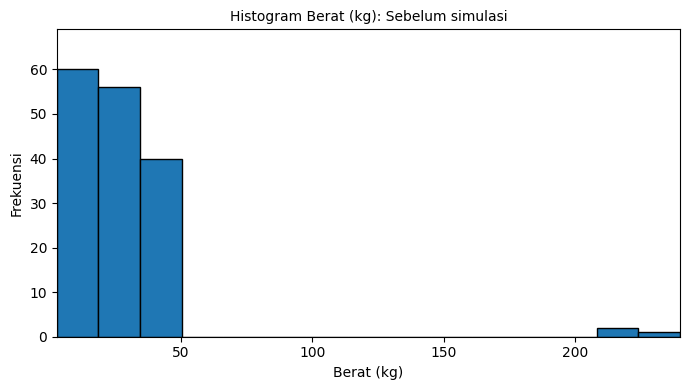

In [ ]:
#HISTOGRAM BERAT (KG) SEBELUM SIMULASI
plt.figure(figsize=(7,4))
plt.hist(berat_awal, bins=bins_berat, edgecolor="black")
plt.xlim(bins_berat[0], bins_berat[-1])
plt.ylim(0, y_berat_hist)
plt.xlabel("Berat (kg)")
plt.ylabel("Frekuensi")
plt.title("Histogram Berat (kg): Sebelum simulasi", fontsize=10)
plt.tight_layout()
plt.show()

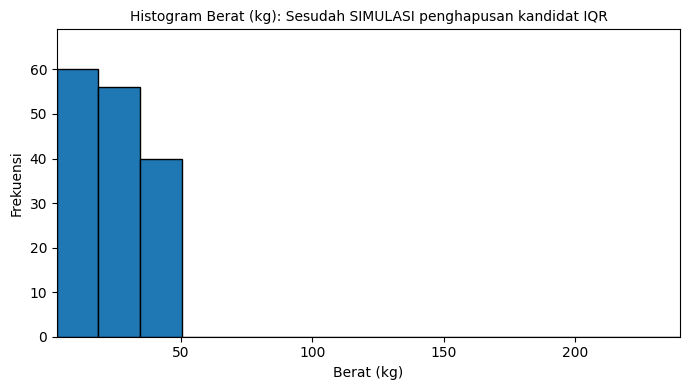

In [ ]:
#HISTOGRAM BERAT (KG) SESUDAH SIMULASI
plt.figure(figsize=(7,4))
plt.hist(berat_simulasi, bins=bins_berat, edgecolor="black")
plt.xlim(bins_berat[0], bins_berat[-1])
plt.ylim(0, y_berat_hist)
plt.xlabel("Berat (kg)")
plt.ylabel("Frekuensi")
plt.title("Histogram Berat (kg): Sesudah SIMULASI penghapusan kandidat IQR", fontsize=10)
plt.tight_layout()
plt.show()

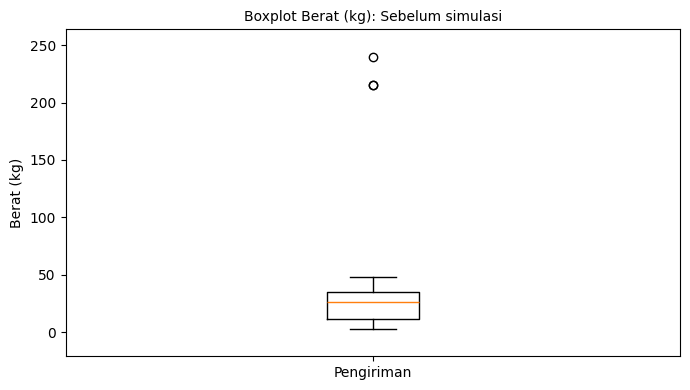

In [ ]:
#BOXPLOT BERAT (KG) SEBELUM SIMULASI
plt.figure(figsize=(7,4))
plt.boxplot(berat_awal)
plt.ylim(*batas_berat)
plt.xticks([1], ["Pengiriman"])
plt.ylabel("Berat (kg)")
plt.title("Boxplot Berat (kg): Sebelum simulasi", fontsize=10)
plt.tight_layout()
plt.show()

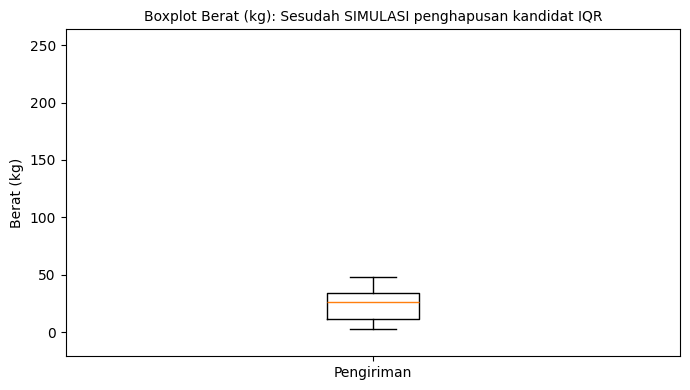

In [ ]:
#BOXPLOT BERAT (KG) SESUDAH SIMULASI
plt.figure(figsize=(7,4))
plt.boxplot(berat_simulasi)
plt.ylim(*batas_berat)
plt.xticks([1], ["Pengiriman"])
plt.ylabel("Berat (kg)")
plt.title("Boxplot Berat (kg): Sesudah SIMULASI penghapusan kandidat IQR", fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
#GRAFIK OUTLIER JARAK (KM)
jarak_outlier_awal = data["jarak_valid"].dropna()
jarak_outlier_simulasi = data.loc[~data["jarak_valid_outlier_IQR"], "jarak_valid"].dropna()
bins_jarak_outlier = np.linspace(jarak_outlier_awal.min(), jarak_outlier_awal.max(), 16)
y_jarak_outlier_hist = max(np.histogram(jarak_outlier_awal, bins=bins_jarak_outlier)[0].max(),
                       np.histogram(jarak_outlier_simulasi, bins=bins_jarak_outlier)[0].max()) * 1.15
rentang_jarak_outlier = jarak_outlier_awal.max() - jarak_outlier_awal.min()
batas_jarak_outlier = (jarak_outlier_awal.min()-0.1*rentang_jarak_outlier, jarak_outlier_awal.max()+0.1*rentang_jarak_outlier)
print("Jumlah nilai sebelum:",len(jarak_outlier_awal),"sesudah simulasi:",len(jarak_outlier_simulasi))
print("Data utama tetap mempertahankan kandidat valid dengan penanda IQR.")

Jumlah nilai sebelum: 156 sesudah simulasi: 156
Data utama tetap mempertahankan kandidat valid dengan penanda IQR.


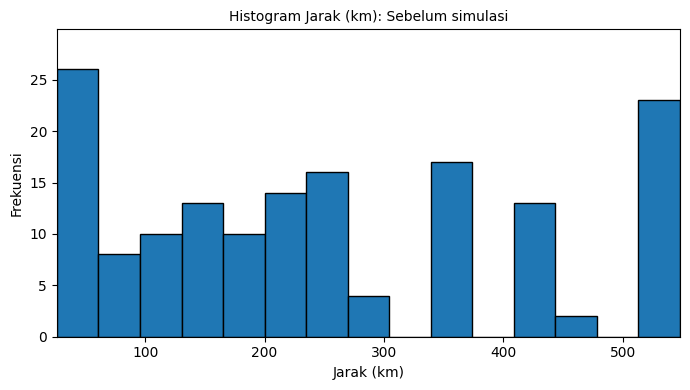

In [ ]:
#HISTOGRAM JARAK (KM) SEBELUM SIMULASI
plt.figure(figsize=(7,4))
plt.hist(jarak_outlier_awal, bins=bins_jarak_outlier, edgecolor="black")
plt.xlim(bins_jarak_outlier[0], bins_jarak_outlier[-1])
plt.ylim(0, y_jarak_outlier_hist)
plt.xlabel("Jarak (km)")
plt.ylabel("Frekuensi")
plt.title("Histogram Jarak (km): Sebelum simulasi", fontsize=10)
plt.tight_layout()
plt.show()

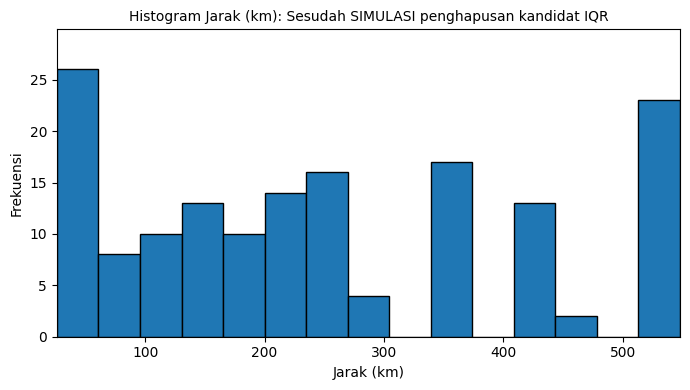

In [ ]:
#HISTOGRAM JARAK (KM) SESUDAH SIMULASI
plt.figure(figsize=(7,4))
plt.hist(jarak_outlier_simulasi, bins=bins_jarak_outlier, edgecolor="black")
plt.xlim(bins_jarak_outlier[0], bins_jarak_outlier[-1])
plt.ylim(0, y_jarak_outlier_hist)
plt.xlabel("Jarak (km)")
plt.ylabel("Frekuensi")
plt.title("Histogram Jarak (km): Sesudah SIMULASI penghapusan kandidat IQR", fontsize=10)
plt.tight_layout()
plt.show()

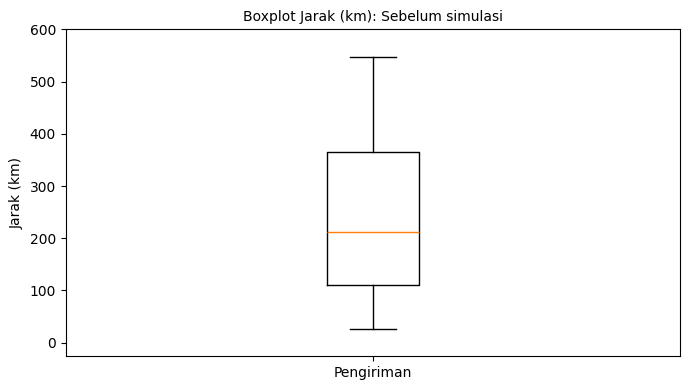

In [ ]:
#BOXPLOT JARAK (KM) SEBELUM SIMULASI
plt.figure(figsize=(7,4))
plt.boxplot(jarak_outlier_awal)
plt.ylim(*batas_jarak_outlier)
plt.xticks([1], ["Pengiriman"])
plt.ylabel("Jarak (km)")
plt.title("Boxplot Jarak (km): Sebelum simulasi", fontsize=10)
plt.tight_layout()
plt.show()

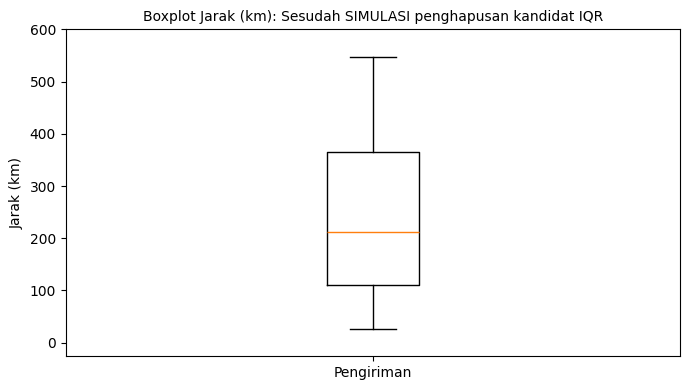

In [ ]:
#BOXPLOT JARAK SESUDAH SIMULASI
plt.figure(figsize=(7,4))
plt.boxplot(jarak_outlier_simulasi)
plt.ylim(*batas_jarak_outlier)
plt.xticks([1], ["Pengiriman"])
plt.ylabel("Jarak (km)")
plt.title("Boxplot Jarak (km): Sesudah SIMULASI penghapusan kandidat IQR", fontsize=10)
plt.tight_layout()
plt.show()

**Soal 8. Transformasi: atribut durasi pengiriman**

In [ ]:
#DETEKSI
display(data[["id_pengiriman","status_pengiriman","waktu_berangkat_utc","waktu_tiba_valid_utc"]].head(10))
print("Pasangan waktu lengkap:",data[["waktu_berangkat_utc","waktu_tiba_valid_utc"]].notna().all(axis=1).sum())

,id_pengiriman,status_pengiriman,waktu_berangkat_utc,waktu_tiba_valid_utc
0,KRM00238,retur,2026-03-12 00:15:00+00:00,2026-03-12 08:15:00+00:00
1,KRM00474,dibatalkan,NaT,NaT
2,KRM00015,terkirim,2026-02-03 10:55:00+00:00,2026-02-04 14:55:00+00:00
3,KRM00687,terkirim,2026-05-26 03:25:00+00:00,2026-05-26 11:25:00+00:00
4,KRM00116,retur,2026-02-20 09:05:00+00:00,2026-02-20 17:05:00+00:00
5,KRM00199,terkirim,2026-03-06 01:45:00+00:00,2026-03-06 08:45:00+00:00
6,KRM00509,terkirim,2026-04-26 03:15:00+00:00,2026-04-26 07:15:00+00:00
7,KRM00577,terkirim,2026-05-08 02:15:00+00:00,2026-05-08 14:15:00+00:00
8,KRM00614,dibatalkan,NaT,NaT
10,KRM00681,terkirim,2026-05-25 06:00:00+00:00,2026-05-25 10:00:00+00:00


Pasangan waktu lengkap: 160


In [ ]:
#SOLUSI
data["durasi_jam"] = (data["waktu_tiba_valid_utc"] - data["waktu_berangkat_utc"]).dt.total_seconds() / 3600
data.loc[data["status_pengiriman"].eq("dibatalkan"),"durasi_jam"] = np.nan
data["durasi_jam"] = data["durasi_jam"].where(data["durasi_jam"] >= 0)
data[["id_pengiriman","durasi_jam"]].head(10)

,id_pengiriman,durasi_jam
0,KRM00238,8.0
1,KRM00474,NaN
2,KRM00015,28.0
3,KRM00687,8.0
4,KRM00116,8.0
5,KRM00199,7.0
6,KRM00509,4.0
7,KRM00577,12.0
8,KRM00614,NaN
10,KRM00681,4.0


In [ ]:
#HASIL
display(data["durasi_jam"].describe())
print("Durasi belum dapat dihitung:",data["durasi_jam"].isnull().sum())
assert data["durasi_jam"].dropna().ge(0).all()

,durasi_jam
count,160.000000
mean,9.025000
std,4.932182
min,3.000000
25%,5.000000
50%,8.000000
75%,12.000000
max,28.000000


Durasi belum dapat dihitung: 16


**Soal 9. Transformasi: ringkasan bulanan per layanan**

In [ ]:
#DETEKSI
data["bulan_utc"] = data["waktu_berangkat_utc"].dt.strftime("%Y-%m")
data[["id_pengiriman","bulan_utc","layanan","durasi_jam"]].head(10)

,id_pengiriman,bulan_utc,layanan,durasi_jam
0,KRM00238,2026-03,prioritas,8.0
1,KRM00474,NaN,ekonomi,NaN
2,KRM00015,2026-02,ekonomi,28.0
3,KRM00687,2026-05,ekonomi,8.0
4,KRM00116,2026-02,ekonomi,8.0
5,KRM00199,2026-03,standar,7.0
6,KRM00509,2026-04,ekonomi,4.0
7,KRM00577,2026-05,prioritas,12.0
8,KRM00614,NaN,standar,NaN
10,KRM00681,2026-05,prioritas,4.0


In [ ]:
#SOLUSI
data_agg = data.groupby(["bulan_utc","layanan"], dropna=False)[
    ["berat_kg","jarak_valid","durasi_jam"]
].mean()
data_agg

berat_kg  jarak_valid  durasi_jam
bulan_utc layanan                                      
2026-02   ekonomi    26.800357   263.818182   10.571429
          prioritas  53.874667   169.375000   12.142857
          standar    24.637125   280.857143   10.750000
          NaN         8.627000   540.000000   16.000000
2026-03   ekonomi    47.505300   327.125000   10.363636
          prioritas  26.857727   286.416667    7.076923
          standar    24.022941   201.250000    8.937500
          NaN        29.771500   291.400000   10.600000
2026-04   ekonomi    24.809000   211.076923    8.571429
          prioritas  26.820714   309.500000    8.600000
          standar    22.542818   205.375000    8.500000
          NaN        23.270000   273.666667    5.000000
2026-05   ekonomi    26.102824   282.375000    8.437500
          prioritas  26.073833   185.000000    8.307692
          standar    30.142083   299.363636    8.583333
          NaN        25.333200   250.600000    7.600000
NaN       ekonomi    13.278000   282.800000         NaN
          standar    18.739000   239.666667         NaN
          NaN        38.057000   133.000000         NaN

In [ ]:
#SOLUSI JUMLAH PENGIRIMAN DAN KELENGKAPAN PENGUKURAN
data_count = data.groupby(["bulan_utc","layanan"], dropna=False)[
    ["id_pengiriman","berat_kg","jarak_valid","durasi_jam"]
].count()
data_count

id_pengiriman  berat_kg  jarak_valid  durasi_jam
bulan_utc layanan                                                    
2026-02   ekonomi               14        14           11          14
          prioritas              8         6            8           7
          standar                8         8            7           8
          NaN                    1         1            1           1
2026-03   ekonomi               11        10            8          11
          prioritas             14        11           12          13
          standar               18        17           16          16
          NaN                    6         6            5           5
2026-04   ekonomi               14        10           13          14
          prioritas             10         7           10          10
          standar               12        11            8          12
          NaN                    3         3            3           3
2026-05   ekonomi               17        17           16          16
          prioritas             14        12           13          13
          standar               12        12           11          12
          NaN                    5         5            5           5
NaN       ekonomi                5         5            5           0
          standar                3         3            3           0
          NaN                    1         1            1           0